In [1]:
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
import sympy as sm

In [2]:
########## Problem 1

# task a

# for this derivation, if we start from V = v1(r + t) + v2(r - t) in real space and then fourier transform, we get that V = v1(q) e^(i q t) + v2(q) e^(-i q t) 
# = v1(q) [cos(qt) + i sin(qt)] + v2(q) [cos(qt) - i sin(qt)] = cos(qt)[v1(q) + v2(q)] + i sin(qt)[v1(q) - v2(q)] = V^S cos(qt) + i V^A sin(qt). The V^A and V^S
# are the atomic form factors, and the sin and cos parts are the geometric phase. 

In [3]:
# task b

# I can just make a list of the representative vectors and calculate q^2, sin(qt), and cos(qt) for those vectors, and print them out. It's not exactly a table,
# but I believe the effect is the same. 

a = 1       # since q is in terms of 2pi/a, the a will cancel out. So I just set it to 1 for convenience
tau = (a/8) * np.array([1, 1, 1])

qs = [(1,1,1),(2,0,0),(2,2,0),(3,1,1)]

print(f"{'Vector':<15}{'q^2':<20}{'sin(q t)':<25}{'cos(q t)':<30}")

for i in range(len(qs)):
    q = (2 * np.pi / a) * np.array(qs[i])
    q2 = qs[i][0]**2 + qs[i][1]**2 + qs[i][2]**2
    sin = np.sin(np.dot(q, tau))
    cos = np.cos(np.dot(q, tau))
    print(f"{str(qs[i]):<15}{q2:<20}{sin:<25.6f}{cos:<30.6f}")

# to verify symmetric extinction for every vector in shell 4 and the antisymmetric extinction in shell 8, I can just check that the sines and cosines are 0
# for their respective shells. 

shell4 = [(2,0,0), (-2,0,0), (0,2,0), (0,-2,0), (0,0,2), (0,0,-2)]
shell8 = [(2,2,0), (2,-2,0), (-2,2,0), (-2,-2,0), (0,2,2), (0,-2,2), (0,2,-2), (0,-2,-2),(2,0,2),(2,0,-2),(-2,0,2),(-2,0,-2)]

print("Shell 4")

for i in range(len(shell4)):
    q = (2 * np.pi / a) * np.array(shell4[i])
    q2 = shell4[i][0]**2 + shell4[i][1]**2 + shell4[i][2]**2
    sin = np.sin(np.dot(q, tau))
    cos = np.cos(np.dot(q, tau))
    print(f"{str(shell4[i]):<15}{q2:<20}{sin:<25.6f}{cos:<30.6f}")

print("Shell 8")

for i in range(len(shell8)):
    q = (2 * np.pi / a) * np.array(shell8[i])
    q2 = shell8[i][0]**2 + shell8[i][1]**2 + shell8[i][2]**2
    sin = np.sin(np.dot(q, tau))
    cos = np.cos(np.dot(q, tau))
    print(f"{str(shell8[i]):<15}{q2:<20}{sin:<25.6f}{cos:<30.6f}")

Vector         q^2                 sin(q t)                 cos(q t)                      
(1, 1, 1)      3                   0.707107                 -0.707107                     
(2, 0, 0)      4                   1.000000                 0.000000                      
(2, 2, 0)      8                   0.000000                 -1.000000                     
(3, 1, 1)      11                  -0.707107                -0.707107                     
Shell 4
(2, 0, 0)      4                   1.000000                 0.000000                      
(-2, 0, 0)     4                   -1.000000                0.000000                      
(0, 2, 0)      4                   1.000000                 0.000000                      
(0, -2, 0)     4                   -1.000000                0.000000                      
(0, 0, 2)      4                   1.000000                 0.000000                      
(0, 0, -2)     4                   -1.000000                0.000000              

In [4]:
# task c

# Starting from H = -(hbar^2 / 2m) del^2 + V and splitting into kinetic and potential parts, we can apply them to plane waves separately. For the kinetic parts,
# we get [-(hbar^2 / 2m) del^2][e^(i (k + G) r) / sqrt(Omega)] = [-(hbar^2 / 2m)] [-|k + G|^2] [e^(i (k + G) r) / sqrt(Omega)] = (hbar^2/2m)(k + G)^2 (phi) and
# taking the inner product gives (hbar^2/2m)(k + G)^2 del_ij, or (hbar^2/2m)(k + G)^2 when i = j and 0 otherwise, equation 6.22 in the book. For the potential 
# parts, going from the book's equation 6.26 for the inner product, we get V(G_i - G_j) = V^S cos(q_ij t) + i V^A sin(q_ij t) for q_ij = G_i - G_j. When i = j, 
# q = 0, and V(0) is conventionally set to be 0. Basically, on the diagonal terms we get only kinetic and on the off diagonal terms we get only potential. 

# As for hermiticity, we just need to consider the off diagonal terms. For V(-q) = V^S cos(-q t) + i V^A sin(-q t) = V^S cos(q t) - i V^A sin(q t), and then the
# complex conjugate part turns it into V^S cos(q t) + i V^A sin(q t), which was the starting point for V(q). 

In [5]:
# task d

# Using the table from problem 2, I can get the V^S and V^A values after converting from rydbergs to eV. I can make the list of Gs by looping through ijk and
# adding the allowed qs. The a value also comes from the table in problem 2. I can then put together the hamiltonian. I also considered the offset for the +2
# eV shift. 

Gamma = np.array([0.0, 0.0, 0.0])
Chi = np.array([1.0, 0.0, 0.0])
L = np.array([0.5, 0.5, 0.5])
random = np.array([np.random.uniform(-1,1), np.random.uniform(-1,1), np.random.uniform(-1,1)])

rydbergToeV = 13.605693122994
GaAs_VS = [-0.23 * rydbergToeV, 0.01 * rydbergToeV, 0.06 * rydbergToeV]
GaAs_VA = [0.07 * rydbergToeV, 0.05 * rydbergToeV, 0.01 * rydbergToeV]

Glist = [(0,0,0)]

for i in range(-3,4):
    for j in range(-3,4):
        for k in range(-3,4):
            if i**2 + j**2 + k**2 in (3,4,8,11):
                Glist.append((i,j,k))

Glist = np.array(Glist)

a = 5.64
h2mEnergy =  3.80998211615486 * (2*np.pi/a)**2

def Hamiltonian(k, offset):
    T = np.zeros((len(Glist), len(Glist)), dtype = complex)

    for i in range(len(Glist)):
        T[i, i] = h2mEnergy * np.sum((k + Glist[i])**2)

    V = np.zeros((len(Glist), len(Glist)), dtype = complex)

    for i in range(len(Glist)):
        for j in range(len(Glist)):
            q = Glist[i] - Glist[j]
            q2 = np.sum(q**2)
            theta = np.pi/4 * np.sum(q)

            VS = 0
            VA = 0

            if q2 == 3:
                VS = GaAs_VS[0]
                VA = GaAs_VA[0]
            if q2 == 4:
                VA = GaAs_VA[1]
            if q2 == 8:
                VS = GaAs_VS[1]
            if q2 == 11:
                VS = GaAs_VS[2]
                VA = GaAs_VA[2]

            V[i, j] = VS*np.cos(theta) + 1j*VA*np.sin(theta)

    H = T + V + offset * np.eye(len(Glist))

    return H

# Last, I just compare the energies with the offset energies. The difference between energies of the offset and no offset is +2 eV, which is expected. The 
# tolerances are also small enough that was can call them machine precision error. 

Energy_Gamma_a = np.linalg.eigvalsh(Hamiltonian(Gamma,0))
Energy_Gamma_b = np.linalg.eigvalsh(Hamiltonian(Gamma,2))
Energy_Chi_a = np.linalg.eigvalsh(Hamiltonian(Chi,0))
Energy_Chi_b = np.linalg.eigvalsh(Hamiltonian(Chi,2))
Energy_L_a = np.linalg.eigvalsh(Hamiltonian(L,0))
Energy_L_b = np.linalg.eigvalsh(Hamiltonian(L,2))
Energy_Rand_a = np.linalg.eigvalsh(Hamiltonian(random,0))
Energy_Rand_b = np.linalg.eigvalsh(Hamiltonian(random,2))

print(Energy_Gamma_a - Energy_Gamma_b)
print(Energy_Chi_a - Energy_Chi_b)
print(Energy_L_a - Energy_L_b)
print(Energy_Rand_a - Energy_Rand_b)

print("Gamma max diff (eV):", np.max(np.abs(Energy_Gamma_b - Energy_Gamma_a - 2)))
print("X max diff (eV):", np.max(np.abs(Energy_Chi_b - Energy_Chi_a - 2)))
print("L max diff (eV):", np.max(np.abs(Energy_L_b - Energy_L_a - 2)))
print("Random max diff (eV):", np.max(np.abs(Energy_Rand_b - Energy_Rand_a - 2)))

[-2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2.
 -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2.
 -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2.]
[-2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2.
 -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2.
 -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2.]
[-2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2.
 -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2.
 -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2.]
[-2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2.
 -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2.
 -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2. -2.]
Gamma max diff (eV): 6.394884621840902e-14
X max diff (eV): 1.8474111129762605e-13
L max diff (eV): 8.704148513061227e-14
Random max diff (eV): 7.105427357601002e-14


In [6]:
########## Problem 2

# table

Si = [(5.43),(-0.21),(0.04),(0.08),(0),(0),(0)]
Ge = [(5.66),(-0.23),(0.01),(0.06),(0),(0),(0)]
alphaSn = [(6.49),(-0.2),(0),(0.04),(0),(0),(0)]
GaP = [(5.44),(-0.22),(0.03),(0.07),(0.12),(0.07),(0.02)]
GaAs = [(5.64),(-0.23),(0.01),(0.06),(0.07),(0.05),(0.01)]
AlSb = [(6.13),(-0.21),(0.02),(0.06),(0.06),(0.04),(0.02)]
InP = [(5.86),(-0.23),(0.01),(0.06),(0.07),(0.05),(0.01)]
GaSb = [(6.12),(-0.22),(0),(0.05),(0.06),(0.05),(0.01)]
InAs = [(6.04),(-0.22),(0),(0.05),(0.08),(0.05),(0.03)]
InSb = [(6.48),(-0.2),(0),(0.04),(0.06),(0.05),(0.01)]
ZnS = [(5.41),(-0.22),(0.03),(0.07),(0.24),(0.14),(0.04)]
ZnSe = [(5.65),(-0.23),(0.01),(0.06),(0.18),(0.12),(0.03)]
ZnTe = [(6.07),(-0.22),(0),(0.05),(0.13),(0.1),(0.01)]
CdTe = [(6.41),(-0.2),(0),(0.04),(0.15),(0.09),(0.04)]

In [7]:
# task a

# This is essentially the same as 1d but with a different cutoff. With a cutoff of 21, k+G can be at most sqrt(21) ~ 4.58. The k point changes for Gamma,
# Chi, L, and the random point. The length of the G list stops growing after 6, but I'll loop through 10 for safety. I just remake the hamiltonian,

def Glister(kpoint, cutoff = 21, N = 10):

    Glist = []

    for i in range(-N, N):
        for j in range(-N, N):
            for k in range(-N, N):
                if i % 2 == j % 2 == k % 2:
                    G = np.array([i, j, k])

                    if np.sum((G + kpoint)**2) <= cutoff:
                        Glist.append(G)

    return np.array(Glist, dtype = int)

def Hamiltonian2(kpoint, a, VS, VA, cutoff = 21):
    Glist = Glister(kpoint, cutoff)
    N = len(Glist)

    h2mEnergy = 3.80998211615486 * (2 * np.pi / a)**2

    T = np.zeros((N, N), dtype = complex)
    V = np.zeros((N, N), dtype = complex)

    for i in range(N):
        G = Glist[i]
        T[i, i] = h2mEnergy * np.sum((kpoint + G)**2)

        for j in range(N):
            q = G - Glist[j]
            q2 = np.sum(q**2)
            theta = np.pi/4 * np.sum(q)

            vs = 0
            va = 0

            if q2 == 3:
                vs, va = VS[0], VA[0]

            if q2 == 4:
                va = VA[1]

            if q2 == 8:
                vs = VS[1]

            if q2 == 11:
                vs, va = VS[2], VA[2]

            V[i, j] = vs*np.cos(theta) + 1j*va*np.sin(theta)

    return T + V

# Ill diagonalize this for Si at the gamma point since no specific one is required

print(np.linalg.eigvalsh(Hamiltonian2(Gamma, Si[0], rydbergToeV * np.array(Si[1:4]), rydbergToeV * np.array(Si[4:7]))))

[ -2.15469742  10.48232887  10.48232887  10.48232887  13.90527755
  13.90527755  13.90527755  14.36632969  18.02212789  18.45072311
  18.45072311  22.87507768  22.87507768  22.87507768  24.69836924
  37.95397303  37.95397303  37.95397303  38.98553413  38.98553413
  39.55604048  39.55604048  39.55604048  41.35249919  41.35249919
  41.35249919  42.69863306  53.25176389  54.53503032  54.53503032
  54.53503032  54.6657007   54.6657007   54.6657007   55.35756209
  55.35756209  55.35756209  55.89090644  55.89090644  55.96408383
  55.96408383  55.96408383  56.28508813  56.28508813  56.28508813
  56.64803308  56.64803308  57.00612149  57.00612149  57.00612149
  57.65055297  61.29764304  62.48591962  62.48591962  62.48591962
  63.92042151  63.92042151  63.92042151  65.51509761  81.96833783
  82.08543791  82.08543791  82.08543791  82.16020033  82.16020033
  93.36499473  93.36499473  93.50798539  93.50798539  93.50798539
  94.49083178  94.49083178  94.49083178  95.13166914  95.13166914
  95.13166

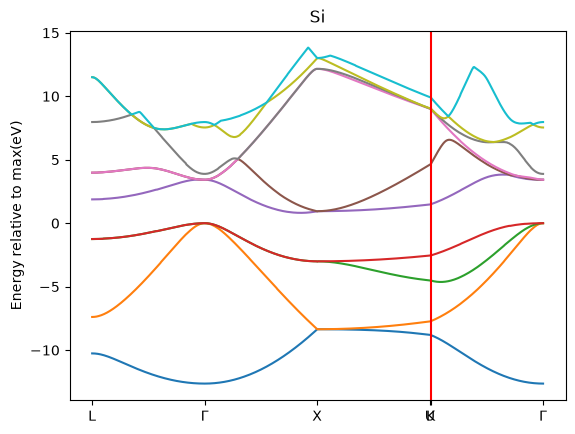

In [8]:
# task b

# I make the paths needed and then get the eigenvalues across the paths. Since only the lower 10 are needed, I only append those. It's also required to set the
# valence band max separately, so I just calculate that. I plot the bands, with the red line splitting U|K, and then repeat this for all the materials. 

Gamma = np.array([0.0, 0.0, 0.0])
Chi = np.array([1.0, 0.0, 0.0])
L = np.array([0.5, 0.5, 0.5])
U = np.array([1,0.25,0.25])
K = np.array([0.75,0.75,0])

LG = np.linspace(L, Gamma, 161)
GX = np.linspace(Gamma, Chi, 161)
XU = np.linspace(Chi, U, 161)
KG = np.linspace(K, Gamma, 161)
fullPath = np.vstack([LG, GX[1:], XU[1:], KG])

bands = []

for kpoint in fullPath:
    energies = np.linalg.eigvalsh(Hamiltonian2(kpoint, Si[0], rydbergToeV * np.array(Si[1:4]), rydbergToeV * np.array(Si[4:7])))
    bands.append(energies[:10])
bands = np.array(bands)
VBM = np.max(bands[:, 3])

bands = bands - VBM

gap1 = np.min(bands[:, 4])
minimum_index1 = np.argmin(bands[:, 4])
minimum_energy1 = bands[minimum_index1, 4]
minimum_k1 = fullPath[minimum_index1]
gamma_gap1 = bands[160, 4] - bands[160, 3]

x = np.arange(len(fullPath))

for i in range(10):
    plt.plot(x, bands[:, i])

plt.xticks([0, 160, 320, 480, 481, 641], ["L", "Γ", "X", "U", "K", "Γ"])

plt.axvline(481, color = "red")
plt.ylabel("Energy relative to max(eV)")
plt.title("Si")
plt.savefig("P2_tb_Si.png", dpi = 600)

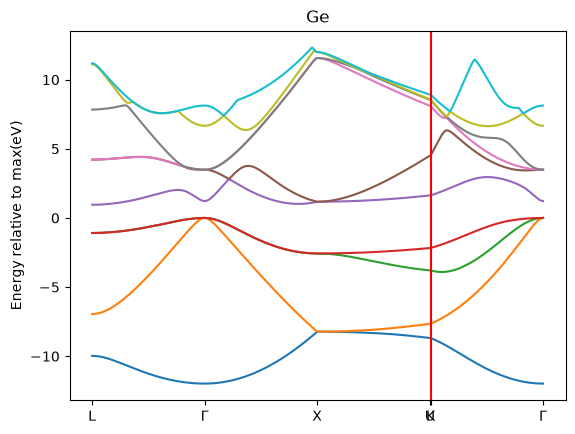

In [9]:
bands = []

for kpoint in fullPath:
    energies = np.linalg.eigvalsh(Hamiltonian2(kpoint, Ge[0], rydbergToeV * np.array(Ge[1:4]), rydbergToeV * np.array(Ge[4:7])))
    bands.append(energies[:10])
bands = np.array(bands)
VBM = np.max(bands[:, 3])

bands = bands - VBM

gap2 = np.min(bands[:, 4])
minimum_index2 = np.argmin(bands[:, 4])
minimum_energy2 = bands[minimum_index2, 4]
minimum_k2 = fullPath[minimum_index2]
gamma_gap2 = bands[160, 4] - bands[160, 3]

x = np.arange(len(fullPath))

for i in range(10):
    plt.plot(x, bands[:, i])

plt.xticks([0, 160, 320, 480, 481, 641], ["L", "Γ", "X", "U", "K", "Γ"])

plt.axvline(481, color = "red")
plt.ylabel("Energy relative to max(eV)")
plt.title("Ge")
plt.savefig("P2_tb_Ge.png", dpi = 600)

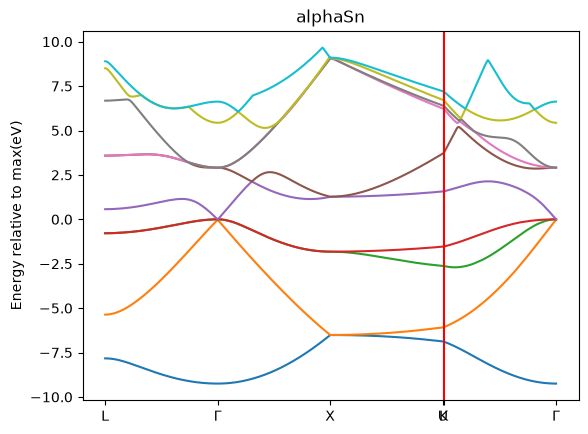

In [10]:
bands = []

for kpoint in fullPath:
    energies = np.linalg.eigvalsh(Hamiltonian2(kpoint, alphaSn[0], rydbergToeV * np.array(alphaSn[1:4]), rydbergToeV * np.array(alphaSn[4:7])))
    bands.append(energies[:10])
bands = np.array(bands)
VBM = np.max(bands[:, 3])

bands = bands - VBM

gap3 = np.min(bands[:, 4])
minimum_index3 = np.argmin(bands[:, 4])
minimum_energy3 = bands[minimum_index3, 4]
minimum_k3 = fullPath[minimum_index3]
gamma_gap3 = bands[160, 4] - bands[160, 3]

x = np.arange(len(fullPath))

for i in range(10):
    plt.plot(x, bands[:, i])

plt.xticks([0, 160, 320, 480, 481, 641], ["L", "Γ", "X", "U", "K", "Γ"])

plt.axvline(481, color = "red")
plt.ylabel("Energy relative to max(eV)")
plt.title("alphaSn")
plt.savefig("P2_tb_alphaSn.png", dpi = 600)

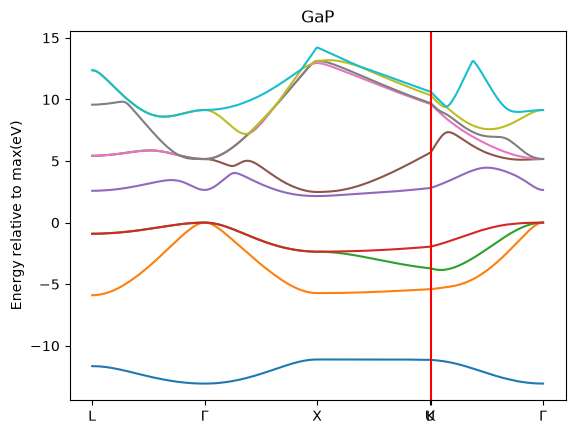

In [11]:
bands = []

for kpoint in fullPath:
    energies = np.linalg.eigvalsh(Hamiltonian2(kpoint, GaP[0], rydbergToeV * np.array(GaP[1:4]), rydbergToeV * np.array(GaP[4:7])))
    bands.append(energies[:10])
bands = np.array(bands)
VBM = np.max(bands[:, 3])

bands = bands - VBM

gap4 = np.min(bands[:, 4])
minimum_index4 = np.argmin(bands[:, 4])
minimum_energy4 = bands[minimum_index4, 4]
minimum_k4 = fullPath[minimum_index4]
gamma_gap4 = bands[160, 4] - bands[160, 3]

x = np.arange(len(fullPath))

for i in range(10):
    plt.plot(x, bands[:, i])

plt.xticks([0, 160, 320, 480, 481, 641], ["L", "Γ", "X", "U", "K", "Γ"])

plt.axvline(481, color = "red")
plt.ylabel("Energy relative to max(eV)")
plt.title("GaP")
plt.savefig("P2_tb_GaP.png", dpi = 600)

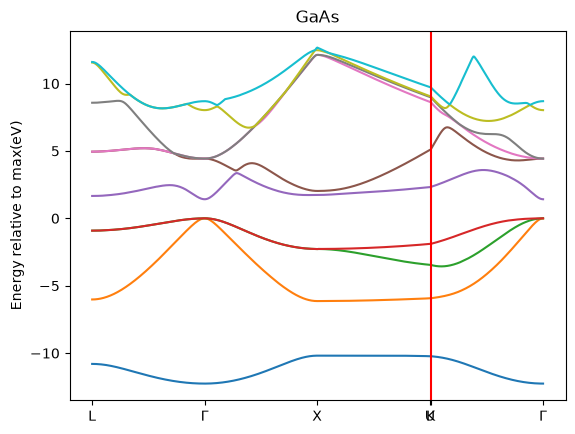

In [12]:
bands = []

for kpoint in fullPath:
    energies = np.linalg.eigvalsh(Hamiltonian2(kpoint, GaAs[0], rydbergToeV * np.array(GaAs[1:4]), rydbergToeV * np.array(GaAs[4:7])))
    bands.append(energies[:10])
bands = np.array(bands)
VBM = np.max(bands[:, 3])

bands = bands - VBM

gap5 = np.min(bands[:, 4])
minimum_index5 = np.argmin(bands[:, 4])
minimum_energy5 = bands[minimum_index5, 4]
minimum_k5 = fullPath[minimum_index5]
gamma_gap5 = bands[160, 4] - bands[160, 3]

x = np.arange(len(fullPath))

for i in range(10):
    plt.plot(x, bands[:, i])

plt.xticks([0, 160, 320, 480, 481, 641], ["L", "Γ", "X", "U", "K", "Γ"])

plt.axvline(481, color = "red")
plt.ylabel("Energy relative to max(eV)")
plt.title("GaAs")
plt.savefig("P2_tb_GaAs.png", dpi = 600)

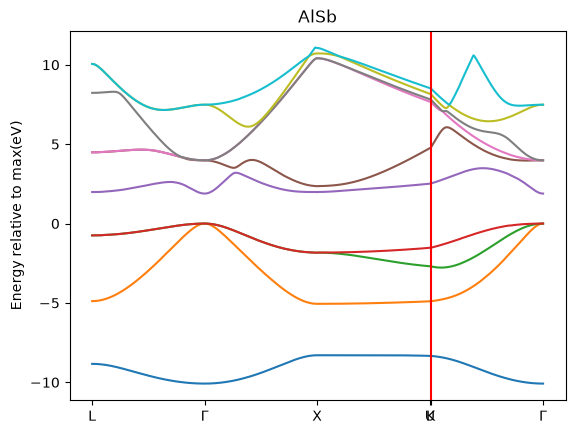

In [13]:
bands = []

for kpoint in fullPath:
    energies = np.linalg.eigvalsh(Hamiltonian2(kpoint, AlSb[0], rydbergToeV * np.array(AlSb[1:4]), rydbergToeV * np.array(AlSb[4:7])))
    bands.append(energies[:10])
bands = np.array(bands)
VBM = np.max(bands[:, 3])

bands = bands - VBM

gap6 = np.min(bands[:, 4])
minimum_index6 = np.argmin(bands[:, 4])
minimum_energy6 = bands[minimum_index6, 4]
minimum_k6 = fullPath[minimum_index6]
gamma_gap6 = bands[160, 4] - bands[160, 3]

x = np.arange(len(fullPath))

for i in range(10):
    plt.plot(x, bands[:, i])

plt.xticks([0, 160, 320, 480, 481, 641], ["L", "Γ", "X", "U", "K", "Γ"])

plt.axvline(481, color = "red")
plt.ylabel("Energy relative to max(eV)")
plt.title("AlSb")
plt.savefig("P2_tb_AlSb.png", dpi = 600)

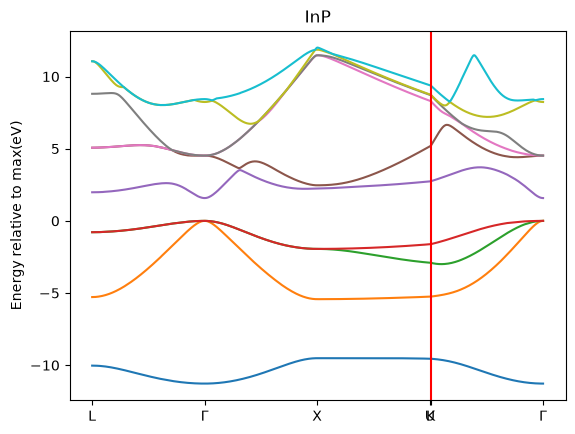

In [14]:
bands = []

for kpoint in fullPath:
    energies = np.linalg.eigvalsh(Hamiltonian2(kpoint, InP[0], rydbergToeV * np.array(InP[1:4]), rydbergToeV * np.array(InP[4:7])))
    bands.append(energies[:10])
bands = np.array(bands)
VBM = np.max(bands[:, 3])

bands = bands - VBM

gap7 = np.min(bands[:, 4])
minimum_index7 = np.argmin(bands[:, 4])
minimum_energy7 = bands[minimum_index7, 4]
minimum_k7 = fullPath[minimum_index7]
gamma_gap7 = bands[160, 4] - bands[160, 3]

x = np.arange(len(fullPath))

for i in range(10):
    plt.plot(x, bands[:, i])

plt.xticks([0, 160, 320, 480, 481, 641], ["L", "Γ", "X", "U", "K", "Γ"])

plt.axvline(481, color = "red")
plt.ylabel("Energy relative to max(eV)")
plt.title("InP")
plt.savefig("P2_tb_InP.png", dpi = 600)

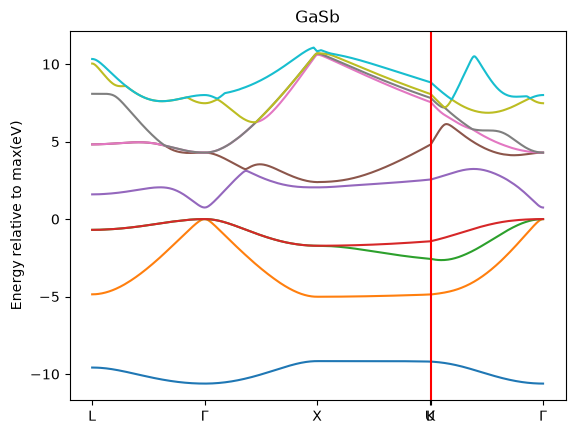

In [15]:
bands = []

for kpoint in fullPath:
    energies = np.linalg.eigvalsh(Hamiltonian2(kpoint, GaSb[0], rydbergToeV * np.array(GaSb[1:4]), rydbergToeV * np.array(GaSb[4:7])))
    bands.append(energies[:10])
bands = np.array(bands)
VBM = np.max(bands[:, 3])

bands = bands - VBM

gap8 = np.min(bands[:, 4])
minimum_index8 = np.argmin(bands[:, 4])
minimum_energy8 = bands[minimum_index8, 4]
minimum_k8 = fullPath[minimum_index8]
gamma_gap8 = bands[160, 4] - bands[160, 3]

x = np.arange(len(fullPath))

for i in range(10):
    plt.plot(x, bands[:, i])

plt.xticks([0, 160, 320, 480, 481, 641], ["L", "Γ", "X", "U", "K", "Γ"])

plt.axvline(481, color = "red")
plt.ylabel("Energy relative to max(eV)")
plt.title("GaSb")
plt.savefig("P2_tb_GaSb.png", dpi = 600)

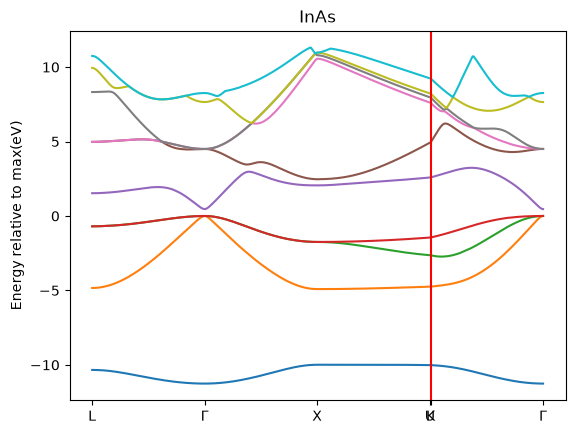

In [16]:
bands = []

for kpoint in fullPath:
    energies = np.linalg.eigvalsh(Hamiltonian2(kpoint, InAs[0], rydbergToeV * np.array(InAs[1:4]), rydbergToeV * np.array(InAs[4:7])))
    bands.append(energies[:10])
bands = np.array(bands)
VBM = np.max(bands[:, 3])

bands = bands - VBM

gap9 = np.min(bands[:, 4])
minimum_index9 = np.argmin(bands[:, 4])
minimum_energy9 = bands[minimum_index9, 4]
minimum_k9 = fullPath[minimum_index9]
gamma_gap9 = bands[160, 4] - bands[160, 3]

x = np.arange(len(fullPath))

for i in range(10):
    plt.plot(x, bands[:, i])

plt.xticks([0, 160, 320, 480, 481, 641], ["L", "Γ", "X", "U", "K", "Γ"])

plt.axvline(481, color = "red")
plt.ylabel("Energy relative to max(eV)")
plt.title("InAs")
plt.savefig("P2_tb_InAs.png", dpi = 600)

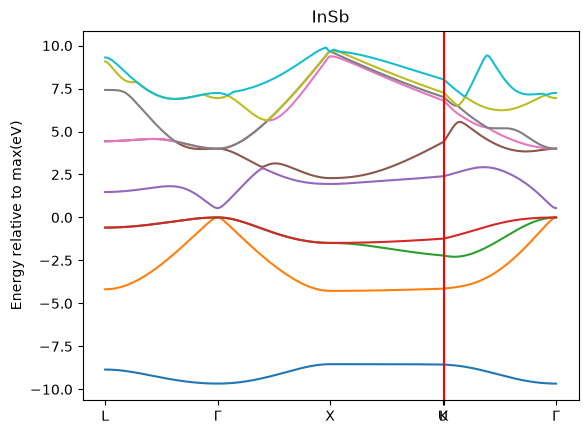

In [17]:
bands = []

for kpoint in fullPath:
    energies = np.linalg.eigvalsh(Hamiltonian2(kpoint, InSb[0], rydbergToeV * np.array(InSb[1:4]), rydbergToeV * np.array(InSb[4:7])))
    bands.append(energies[:10])
bands = np.array(bands)
VBM = np.max(bands[:, 3])

bands = bands - VBM

gap10 = np.min(bands[:, 4])
minimum_index10 = np.argmin(bands[:, 4])
minimum_energy10 = bands[minimum_index10, 4]
minimum_k10 = fullPath[minimum_index10]
gamma_gap10 = bands[160, 4] - bands[160, 3]

x = np.arange(len(fullPath))

for i in range(10):
    plt.plot(x, bands[:, i])

plt.xticks([0, 160, 320, 480, 481, 641], ["L", "Γ", "X", "U", "K", "Γ"])

plt.axvline(481, color = "red")
plt.ylabel("Energy relative to max(eV)")
plt.title("InSb")
plt.savefig("P2_tb_InSb.png", dpi = 600)

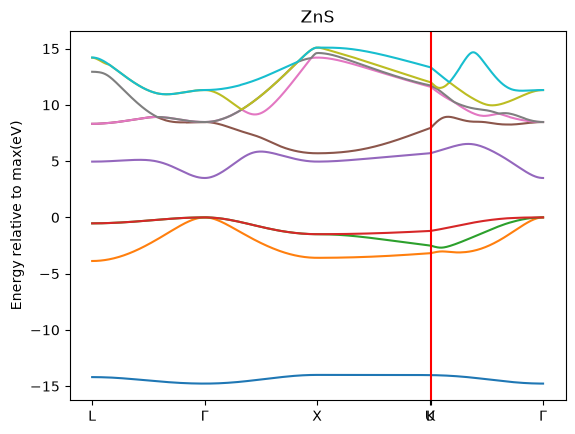

In [18]:
bands = []

for kpoint in fullPath:
    energies = np.linalg.eigvalsh(Hamiltonian2(kpoint, ZnS[0], rydbergToeV * np.array(ZnS[1:4]), rydbergToeV * np.array(ZnS[4:7])))
    bands.append(energies[:10])
bands = np.array(bands)
VBM = np.max(bands[:, 3])

bands = bands - VBM

gap11 = np.min(bands[:, 4])
minimum_index11 = np.argmin(bands[:, 4])
minimum_energy11 = bands[minimum_index11, 4]
minimum_k11 = fullPath[minimum_index11]
gamma_gap11 = bands[160, 4] - bands[160, 3]

x = np.arange(len(fullPath))

for i in range(10):
    plt.plot(x, bands[:, i])

plt.xticks([0, 160, 320, 480, 481, 641], ["L", "Γ", "X", "U", "K", "Γ"])

plt.axvline(481, color = "red")
plt.ylabel("Energy relative to max(eV)")
plt.title("ZnS")
plt.savefig("P2_tb_ZnS.png", dpi = 600)

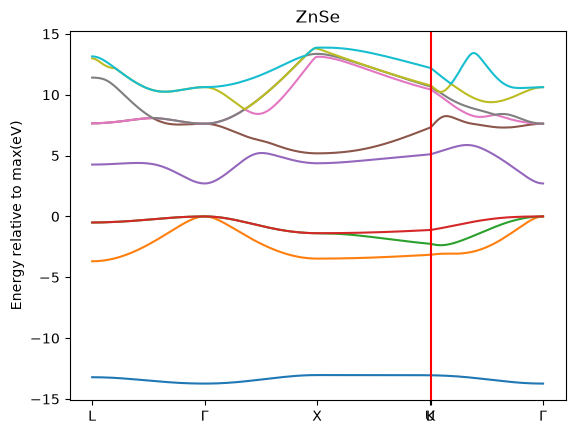

In [19]:
bands = []

for kpoint in fullPath:
    energies = np.linalg.eigvalsh(Hamiltonian2(kpoint, ZnSe[0], rydbergToeV * np.array(ZnSe[1:4]), rydbergToeV * np.array(ZnSe[4:7])))
    bands.append(energies[:10])
bands = np.array(bands)
VBM = np.max(bands[:, 3])

bands = bands - VBM

gap12 = np.min(bands[:, 4])
minimum_index12 = np.argmin(bands[:, 4])
minimum_energy12 = bands[minimum_index12, 4]
minimum_k12 = fullPath[minimum_index12]
gamma_gap12 = bands[160, 4] - bands[160, 3]

x = np.arange(len(fullPath))

for i in range(10):
    plt.plot(x, bands[:, i])

plt.xticks([0, 160, 320, 480, 481, 641], ["L", "Γ", "X", "U", "K", "Γ"])

plt.axvline(481, color = "red")
plt.ylabel("Energy relative to max(eV)")
plt.title("ZnSe")
plt.savefig("P2_tb_ZnSe.png", dpi = 600)

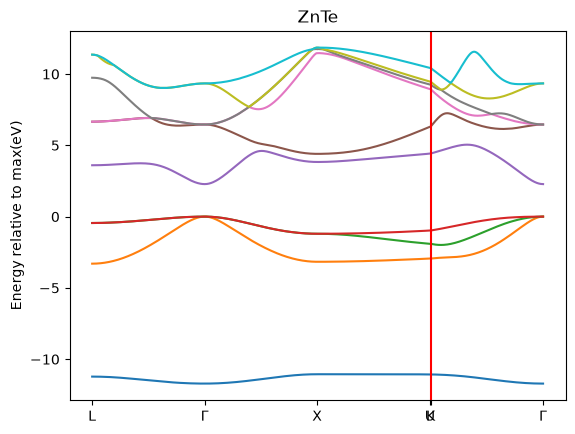

In [20]:
bands = []

for kpoint in fullPath:
    energies = np.linalg.eigvalsh(Hamiltonian2(kpoint, ZnTe[0], rydbergToeV * np.array(ZnTe[1:4]), rydbergToeV * np.array(ZnTe[4:7])))
    bands.append(energies[:10])
bands = np.array(bands)
VBM = np.max(bands[:, 3])

bands = bands - VBM

gap13 = np.min(bands[:, 4])
minimum_index13 = np.argmin(bands[:, 4])
minimum_energy13 = bands[minimum_index13, 4]
minimum_k13 = fullPath[minimum_index13]
gamma_gap13 = bands[160, 4] - bands[160, 3]

x = np.arange(len(fullPath))

for i in range(10):
    plt.plot(x, bands[:, i])

plt.xticks([0, 160, 320, 480, 481, 641], ["L", "Γ", "X", "U", "K", "Γ"])

plt.axvline(481, color = "red")
plt.ylabel("Energy relative to max(eV)")
plt.title("ZnTe")
plt.savefig("P2_tb_ZnTe.png", dpi = 600)

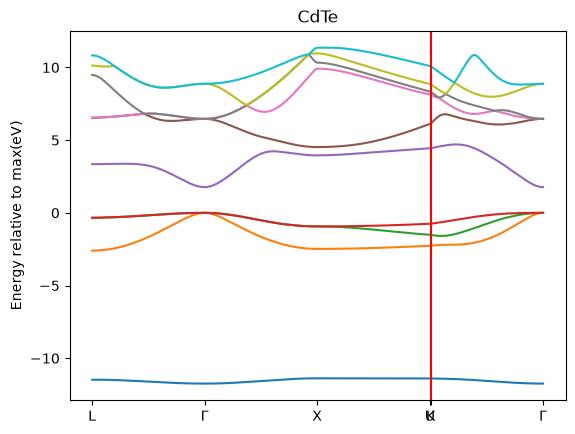

In [21]:
bands = []

for kpoint in fullPath:
    energies = np.linalg.eigvalsh(Hamiltonian2(kpoint, CdTe[0], rydbergToeV * np.array(CdTe[1:4]), rydbergToeV * np.array(CdTe[4:7])))
    bands.append(energies[:10])
bands = np.array(bands)
VBM = np.max(bands[:, 3])

bands = bands - VBM

gap14 = np.min(bands[:, 4])
minimum_index14 = np.argmin(bands[:, 4])
minimum_energy14 = bands[minimum_index14, 4]
minimum_k14 = fullPath[minimum_index14]
gamma_gap14 = bands[160, 4] - bands[160, 3]

x = np.arange(len(fullPath))

for i in range(10):
    plt.plot(x, bands[:, i])

plt.xticks([0, 160, 320, 480, 481, 641], ["L", "Γ", "X", "U", "K", "Γ"])

plt.axvline(481, color = "red")
plt.ylabel("Energy relative to max(eV)")
plt.title("CdTe")
plt.savefig("P2_tb_CdTe.png", dpi = 600)

In [22]:
# task c

# For this task, I went back through all of the previous cells and just added the needed calculations. Since the bands are scaled to their max,
# I can get the gap by just looking at the minimum of the first conduction band. 

print(f"{'Material':<15}{'Path samp gap (eV)':<25}{'Cond min (eV)':<30}{'Cond min kpoint':<40}{'Direct gap (eV)':<50}")
print(f"{'Si':<15}{gap1:<25}{minimum_energy1:<30}{str(minimum_k1):<40}{gamma_gap1:<50}")
print(f"{'Ge':<15}{gap2:<25}{minimum_energy2:<30}{str(minimum_k2):<40}{gamma_gap2:<50}")
print(f"{'alphaSn':<15}{gap3:<25}{minimum_energy3:<30}{str(minimum_k3):<40}{gamma_gap3:<50}")
print(f"{'GaP':<15}{gap4:<25}{minimum_energy4:<30}{str(minimum_k4):<40}{gamma_gap4:<50}")
print(f"{'GaAs':<15}{gap5:<25}{minimum_energy5:<30}{str(minimum_k5):<40}{gamma_gap5:<50}")
print(f"{'AlSb':<15}{gap6:<25}{minimum_energy6:<30}{str(minimum_k6):<40}{gamma_gap6:<50}")
print(f"{'InP':<15}{gap7:<25}{minimum_energy7:<30}{str(minimum_k7):<40}{gamma_gap7:<50}")
print(f"{'GaSb':<15}{gap8:<25}{minimum_energy8:<30}{str(minimum_k8):<40}{gamma_gap8:<50}")
print(f"{'InAs':<15}{gap9:<25}{minimum_energy9:<30}{str(minimum_k9):<40}{gamma_gap9:<50}")
print(f"{'InSb':<15}{gap10:<25}{minimum_energy10:<30}{str(minimum_k10):<40}{gamma_gap10:<50}")
print(f"{'ZnS':<15}{gap11:<25}{minimum_energy11:<30}{str(minimum_k11):<40}{gamma_gap11:<50}")
print(f"{'ZnSe':<15}{gap12:<25}{minimum_energy12:<30}{str(minimum_k12):<40}{gamma_gap12:<50}")
print(f"{'ZnTe':<15}{gap13:<25}{minimum_energy13:<30}{str(minimum_k13):<40}{gamma_gap13:<50}")
print(f"{'CdTe':<15}{gap14:<25}{minimum_energy14:<30}{str(minimum_k14):<40}{gamma_gap14:<50}")

# I think it would be reasonable to say that alphaSn has a gap of 0 and the result seen here is just a precision roundoff

Material       Path samp gap (eV)       Cond min (eV)                 Cond min kpoint                         Direct gap (eV)                                   
Si             0.8139410871366319       0.8139410871366319            [0.85625 0.      0.     ]               3.422948688472566                                 
Ge             0.954669054654051        0.954669054654051             [0.5 0.5 0.5]                           1.222194440900429                                 
alphaSn        7.72715225139109e-14     7.72715225139109e-14          [0. 0. 0.]                              7.72715225139109e-14                              
GaP            2.1480793750700204       2.1480793750700204            [1. 0. 0.]                              2.6532014331621276                                
GaAs           1.4167704296285262       1.4167704296285262            [0. 0. 0.]                              1.4167704296285262                                
AlSb           1.887670363145638  

In [44]:
# task d

# Instead of repasting everything like before, I made a function to do basically the same thing. The only large error is on alphaSn, which has 
# another gap of 0 to machine precision, but that machine precision seems to vary a bit, hence the 20% error. 

def taskD(material):
    a = material[0]
    VS = rydbergToeV * np.array(material[1:4])
    VA = rydbergToeV * np.array(material[4:7])

    points = [("Gamma", Gamma), ("X", Chi), ("L", L)]

    print(f"{'Point':<15}{'Gap 21 (eV)':<30}{'Gap 27 (eV)':<30}{'Error (%)':<15}")

    for name, kpoint in points:
        E21 = sp.linalg.eigh(Hamiltonian2(kpoint, a, VS, VA, cutoff = 21), eigvals_only = True, subset_by_index = [0, 4])
        E27 = sp.linalg.eigh(Hamiltonian2(kpoint, a, VS, VA, cutoff = 27), eigvals_only = True, subset_by_index = [0, 4])
        gap21 = E21[4] - E21[3]
        gap27 = E27[4] - E27[3]
        error = 100 * abs(gap27 - gap21) / abs(gap27) if abs(gap27) > 0 else np.nan

        print(f"{name:<15}{gap21:<30}{gap27:<30}{error:<15}")

print("Material: Si")
taskD(Si)
print("Material: Ge")
taskD(Ge)
print("Material: alphaSn")
taskD(alphaSn)
print("Material: GaP")
taskD(GaP)
print("Material: GaAs")
taskD(GaAs)
print("Material: AlSb")
taskD(AlSb)
print("Material: InP")
taskD(InP)
print("Material: GaSb")
taskD(GaSb)
print("Material: InAs")
taskD(InAs)
print("Material: InSb")
taskD(InSb)
print("Material: ZnS")
taskD(ZnS)
print("Material: ZnSe")
taskD(ZnSe)
print("Material: ZnTe")
taskD(ZnTe)
print("Material: CdTe")
taskD(CdTe)

Material: Si
Point          Gap 21 (eV)                   Gap 27 (eV)                   Error (%)      
Gamma          3.422948688472683             3.4238698725532046            0.02690476317181145
X              3.9515567313114612            3.95397896022038              0.061260541173532884
L              3.124293670854076             3.128127043233359             0.12254529072197888
Material: Ge
Point          Gap 21 (eV)                   Gap 27 (eV)                   Error (%)      
Gamma          1.2221944409005498            1.2227837918553544            0.04819747846921226
X              3.7442583710168353            3.745466920787398             0.032266998911538544
L              2.0429276278490036            2.0432652918986065            0.016525707696484898
Material: alphaSn
Point          Gap 21 (eV)                   Gap 27 (eV)                   Error (%)      
Gamma          1.4210854715202004e-14        1.7763568394002505e-14        20.0           
X              3.09

In [ ]:
# task e

# The group IV materials all have V^A of 0, and generally have their gap not at gamma. The exception is alphaSn, which has a gap of 0. The III-V
# materials generally have their gap at gamma, with the exceptions of GaP. The II-VI materials also have their gap at gamma. As with anything else
# in solid state where calculations don't match experiment, it's likely a mismatch between the approximations used and the impact of those approximations. 
